# 17 — Amortized Inference and the Validation Gates

Every method so far solved an optimisation problem per window. An
**amortized** posterior pays that cost once, at training time, and
thereafter maps observations to a posterior in a single forward pass —
the difference between a research code and a real-time one. This
notebook trains vardax's [`AmortizedPosterior`](xref:api#vardax.AmortizedPosterior)
on simulated Lorenz-63 windows, compares it with a strong-constraint
4DVar oracle, and runs the three validation gates of chapter
[14](../14_six_step_cycle.md) that decide whether such a model may be
trusted. Chapter [10](../10_amortized_inference.md) is the reference.

## What is being learned

We want a conditional density $q_\phi(x \mid y)$ close to the true
posterior $p(x \mid y)$ for *every* $y$ we might see, not just one.
The natural objective averages the Kullback–Leibler divergence over
observations,

$$
\mathcal{L}(\phi) = \mathbb{E}_{y \sim p(y)}\,
  \mathrm{KL}\big(p(\cdot \mid y)\,\|\,q_\phi(\cdot \mid y)\big)
= -\,\mathbb{E}_{(x, y) \sim p(x, y)}\,\log q_\phi(x \mid y) + \text{const},
$$

and the identity on the right is the whole trick: the expectation over
the intractable posterior becomes an expectation over the *joint*,
which we can sample by simulation — draw $x$ from the prior, push it
through the observation model to get $y$. Maximum likelihood on
simulated pairs is therefore posterior matching in expectation. Note
the direction of the divergence: $q_\phi$ is fitted to cover $p$, so a
limited family tends to be *wider* than the truth rather than
narrower, but only in expectation over $y$ and only within the family.

The family here is the [`RegressionHead`](xref:api#vardax.RegressionHead): a
Gaussian with a mean and a diagonal covariance, both functions of a
context vector produced by an [`MLPObsEncoder`](xref:api#vardax.MLPObsEncoder)
from the observations and their mask. Its mean is trained toward the
posterior *mean* (a diagonal Gaussian's likelihood is maximised by
matching first and second moments), which for a symmetric posterior
coincides with the MAP that 4DVar computes and for a skewed one does
not. Its diagonal covariance cannot represent posterior correlations —
the strong $x$–$y$ correlation of notebook
[14](14_posterior_uncertainty_L63.ipynb), for instance — and reports
marginal variances only. Flow and score-based heads lift that
restriction; the regression head is the baseline against which they
should be judged.

Two other things are implicit in the objective. The prior is whatever
distribution the training windows were drawn from — here the Lorenz-63
attractor, not a Gaussian, which is more informative than any $B$ a
variational method would use. And the *amortization gap*: a network of
finite capacity trained on finite data does not reach the optimum of
the family for every $y$, so even in-distribution its posterior is a
little worse than the best diagonal Gaussian would be.

## Why the gates

A variational solver that fails is loud — it does not converge, or its
cost stays high. An amortized network that fails is silent: it returns
a mean and a variance with the same confidence whether the input
resembles its training data or not. Chapter 14 therefore requires
three checks against a slow, trusted oracle before an amortized head
is used operationally:

1. **Posterior agreement.** The amortized mean lies within a few
   oracle standard deviations of the oracle MAP.
2. **Adjoint calibration.** The amortized map $y \mapsto x^*$ has the
   same *sensitivity* to the data as the oracle: their Jacobians agree
   in operator norm. A model can match the oracle on average and still
   respond to perturbations of $y$ in the wrong direction, which is
   what matters when its output feeds a downstream optimisation.
3. **Simulation-based calibration.** Over many simulated windows, the
   rank of the truth among posterior samples is uniform.

The oracle is strong-constraint 4DVar with a Gaussian climatological
prior, its posterior the Laplace approximation of notebook 14 pushed
through the tangent-linear model onto the window. An oracle has to be
*reliable* before it can be trusted to grade anything, and a short
window with a weak prior has a multimodal cost — notebook 14's local
minima — so the oracle is run from several starting points and keeps
the lowest cost. Its prior is not the attractor the network learned
from, and the gates below are read with that in mind: the question is
not whether the two agree to the last digit, but whether the fast
model is close enough, and wrong in the ways the diagnostics predict.

In [1]:
import time

import diffrax as dfx
import equinox as eqx
import jax
import jax.numpy as jnp
import lineax as lx
import matplotlib.pyplot as plt
import numpy as np
import optax
import optimistix as optx
from scipy import stats

from vardax import (
    AmortizedConfig,
    AmortizedPosterior,
    Batch1D,
    DynTrajectory,
    Lorenz63,
    MLPObsEncoder,
    Posterior,
    RegressionHead,
    SoftBoundedForward,
    amortized_train_step,
    assert_adjoint_calibrated,
    assert_posterior_agreement,
    simulate_lorenz63,
    simulation_based_calibration,
)

## 1. Simulated training pairs

Windows of ten states at $\Delta t = 0.05$, cut from one long
trajectory on the attractor; $x$ and $y$ observed at every other step
with noise $\sigma_o = 0.5$, $z$ never. The first 80 % of the
trajectory (in time) provides the training windows and the last 20 %
the test windows, so the test set is not a reshuffle of the training
set. States are standardised per component with training-set
statistics; the network sees standardised inputs and predicts
standardised states, and everything is mapped back before scoring.

In [2]:
DT, T_WIN, SUBSAMPLE = 0.05, 10, 5
SIGMA_OBS = 0.5
mask = jnp.zeros((T_WIN, 3)).at[::2, :2].set(1.0)

_, states = simulate_lorenz63(jax.random.PRNGKey(0), dt=DT / SUBSAMPLE, n_steps=60_000, n_burn_in=2_000)
states = states[::SUBSAMPLE]  # (12001, 3) at spacing DT
n_split = int(0.8 * states.shape[0])
starts_train = jnp.arange(0, n_split - T_WIN)
starts_test = jnp.arange(n_split, states.shape[0] - T_WIN)
x_train = jax.vmap(lambda s: jax.lax.dynamic_slice_in_dim(states, s, T_WIN))(starts_train)
x_test = jax.vmap(lambda s: jax.lax.dynamic_slice_in_dim(states, s, T_WIN))(starts_test)
MU, SD = x_train.mean(axis=(0, 1)), x_train.std(axis=(0, 1))
print(f"train windows {x_train.shape[0]}, test windows {x_test.shape[0]}; component std {SD}")


def observe(x, key):
    return (x + SIGMA_OBS * jax.random.normal(key, x.shape)) * mask


def to_batch(x, key):
    """Simulated (x, y) pairs as a standardised Batch1D with target = x."""
    y = observe(x, key)
    return Batch1D(input=(y - MU * mask) / SD, mask=jnp.broadcast_to(mask, y.shape), target=(x - MU) / SD)


def unstandardise(z):
    return z * SD + MU

train windows 9590, test windows 2391; component std [7.925278  9.000011  8.6006155]


## 2. Training by maximum likelihood on simulated pairs

Fresh observation noise is drawn for every minibatch, so the network
never sees the same $(x, y)$ pair twice; the truth windows repeat but
the data do not. The objective is `amortized_nll_loss_fn`, the
negative log-density of the true window under the predicted Gaussian,
which trains mean and variance together.

parameters: 114620


trained in 38 s; NLL 42.61 -> -59.58


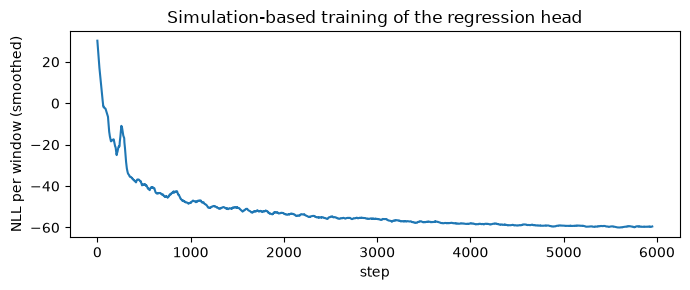

In [3]:
CONTEXT_DIM, HIDDEN = 128, 128
k_enc, k_head = jax.random.split(jax.random.PRNGKey(1))
model = AmortizedPosterior(
    encoder=MLPObsEncoder(input_size=T_WIN * 3, context_dim=CONTEXT_DIM, hidden_dim=HIDDEN, depth=2, key=k_enc),
    head=RegressionHead(context_dim=CONTEXT_DIM, state_shape=(T_WIN, 3), hidden_dim=HIDDEN, depth=2, key=k_head),
    config=AmortizedConfig(head_type="regression", n_samples=100),
)
n_params = sum(p.size for p in jax.tree_util.tree_leaves(eqx.filter(model, eqx.is_array)))
print(f"parameters: {n_params}")

N_STEPS, BATCH = 6000, 256
optimizer = optax.adam(optax.cosine_decay_schedule(1e-3, N_STEPS))
opt_state = optimizer.init(eqx.filter(model, eqx.is_array))
losses = []
t0 = time.time()
for step, k in enumerate(jax.random.split(jax.random.PRNGKey(2), N_STEPS)):
    k_idx, k_noise = jax.random.split(k)
    idx = jax.random.choice(k_idx, x_train.shape[0], (BATCH,), replace=False)
    model, opt_state, loss = amortized_train_step(model, to_batch(x_train[idx], k_noise), optimizer, opt_state)
    losses.append(float(loss))
print(f"trained in {time.time() - t0:.0f} s; NLL {losses[0]:.2f} -> {np.mean(losses[-100:]):.2f}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"), color="tab:blue")
ax.set_xlabel("step")
ax.set_ylabel("NLL per window (smoothed)")
ax.set_title("Simulation-based training of the regression head")
plt.tight_layout()
plt.show()

## 3. The oracle: multi-start strong-constraint 4DVar

For each test window the oracle minimises the 4DVar cost over the
initial state with a Gaussian prior fitted to the attractor's
climatology (its mean and per-component variance). The cost is the one
[`StrongFourDVar`](xref:api#vardax.StrongFourDVar) minimises, written out here so
that the minimiser can be started from eight points — the
climatological mean and seven draws from the prior — with the lowest
cost kept; a single start from the mean lands in a wrong basin on a
sizeable fraction of windows. The posterior is the Gauss–Newton
Laplace covariance pushed through the tangent-linear model to every
time in the window, exactly as in notebook 14. The amortized model's
posterior on the same window is its own Gaussian output. Both are
wrapped as [`Posterior`](xref:api#vardax.Posterior) objects so the gates can
consume them.

windows where the start at the climatological mean was not the best: 95 of 120


120 windows: oracle 4DVar (8 starts) 32.5 s incl. compile, amortized 0.11 s incl. compile, 0.6 ms warm
RMSE per component, oracle   : [0.25508162 0.31504965 0.8041146 ]
RMSE per component, amortized: [0.23078784 0.3484277  0.98401517]
mean posterior std, oracle   : [0.21258284 0.2770065  0.5708738 ]
mean posterior std, amortized: [0.2019139  0.29276347 0.58895636]


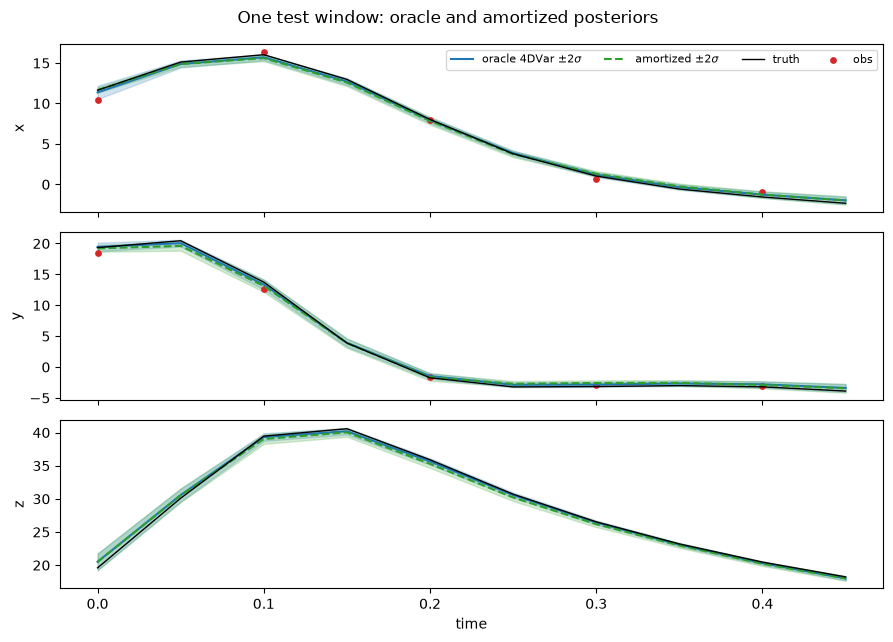

In [4]:
ode = DynTrajectory(model=Lorenz63(sigma=10.0, rho=28.0, beta=8.0 / 3.0), adjoint=dfx.DirectAdjoint())
forward = SoftBoundedForward(ode.as_forward_model(dt=DT), bound=60.0)
X_B_CLIM = MU
B_CLIM = lx.TaggedLinearOperator(lx.DiagonalLinearOperator(SD**2), lx.positive_semidefinite_tag)
R_OP = lx.TaggedLinearOperator(lx.DiagonalLinearOperator(jnp.full(3, SIGMA_OBS**2)), lx.positive_semidefinite_tag)
N_STARTS = 8
starts = jnp.concatenate([X_B_CLIM[None], X_B_CLIM + SD * jax.random.normal(jax.random.PRNGKey(6), (N_STARTS - 1, 3))])


def rollout(x0):
    def step(x, _):
        x_new = forward.step(x, DT)
        return x_new, x_new

    _, rest = jax.lax.scan(step, x0, None, length=T_WIN - 1)
    return jnp.concatenate([x0[None], rest], axis=0)


def cost_4dvar(x0, y):
    """The StrongFourDVar cost with the climatological prior and diagonal R."""
    j_bg = 0.5 * jnp.sum((x0 - X_B_CLIM) ** 2 / SD**2)
    r = mask * (y - rollout(x0))
    return j_bg + 0.5 * jnp.sum(r**2) / SIGMA_OBS**2


def minimise_from(x0_init, y):
    sol = optx.minimise(cost_4dvar, optx.BFGS(rtol=1e-6, atol=1e-6), x0_init, args=y,
                        max_steps=300, adjoint=optx.ImplicitAdjoint(), throw=False)
    return sol.value


@jax.jit
def oracle_solve(y):
    """Multi-start MAP trajectory and its (T_WIN*3 x T_WIN*3) Laplace covariance, batched over windows.

    The (start, window) pairs are flattened into one batch so that a single
    vmap covers the BFGS solves; nesting a vmap over starts inside a vmap over
    windows compiles pathologically slowly.
    """
    n = y.shape[0]
    xs = jnp.tile(starts, (n, 1))  # (n * N_STARTS, 3)
    ys = jnp.repeat(y, N_STARTS, axis=0)  # (n * N_STARTS, T_WIN, 3)
    cands = jax.vmap(minimise_from)(xs, ys)
    costs = jax.vmap(cost_4dvar)(cands, ys).reshape(n, N_STARTS)
    best = jnp.argmin(costs, axis=1)
    x0 = cands.reshape(n, N_STARTS, 3)[jnp.arange(n), best]

    def posterior(x0_i):
        G = jax.jacfwd(lambda x: (mask * rollout(x)).ravel())(x0_i)
        P0 = jnp.linalg.inv(jnp.diag(1.0 / SD**2) + G.T @ G / SIGMA_OBS**2)
        M = jax.jacfwd(rollout)(x0_i).reshape(T_WIN * 3, 3)
        return rollout(x0_i), M @ P0 @ M.T

    traj, cov = jax.vmap(posterior)(x0)
    return traj, cov, best


@jax.jit
def amortized_solve(y):
    """Mean trajectory and diagonal variance from the amortized model, in physical units."""
    # Multiply by the mask before standardising so that, when this map is
    # differentiated, perturbations of unobserved entries cannot reach the
    # encoder (they are identically zero in training and carry no information).
    batch = Batch1D(input=(y * mask - MU * mask) / SD, mask=jnp.broadcast_to(mask, y.shape))
    mean = jax.vmap(lambda ctx: model.head.map_estimate(ctx))(jax.vmap(model.encoder)(batch.input, batch.mask))
    log_var = jax.vmap(lambda ctx: model.head.mlp_log_var(ctx).reshape(T_WIN, 3))(jax.vmap(model.encoder)(batch.input, batch.mask))
    return unstandardise(mean), jnp.exp(log_var) * SD**2


N_EVAL = 120
k_eval = jax.random.PRNGKey(3)
x_eval = x_test[jnp.linspace(0, x_test.shape[0] - 1, N_EVAL).astype(int)]
y_eval = jax.vmap(observe)(x_eval, jax.random.split(k_eval, N_EVAL))

t0 = time.time()
traj_oracle, cov_oracle, best_start = oracle_solve(y_eval)
traj_oracle.block_until_ready()
t_oracle = time.time() - t0
print(f"windows where the start at the climatological mean was not the best: "
      f"{int(jnp.sum(best_start != 0))} of {N_EVAL}")
t0 = time.time()
mean_amort, var_amort = amortized_solve(y_eval)
mean_amort.block_until_ready()
t_amort = time.time() - t0
# second call: compiled
t0 = time.time()
mean_amort, var_amort = amortized_solve(y_eval)
mean_amort.block_until_ready()
t_amort_warm = time.time() - t0

err_oracle = jnp.sqrt(jnp.mean((traj_oracle - x_eval) ** 2, axis=(0, 1)))
err_amort = jnp.sqrt(jnp.mean((mean_amort - x_eval) ** 2, axis=(0, 1)))
print(f"{N_EVAL} windows: oracle 4DVar ({N_STARTS} starts) {t_oracle:.1f} s incl. compile, amortized {t_amort:.2f} s incl. compile, {t_amort_warm * 1e3:.1f} ms warm")
print("RMSE per component, oracle   :", err_oracle)
print("RMSE per component, amortized:", err_amort)
print("mean posterior std, oracle   :", jnp.sqrt(jnp.diagonal(cov_oracle, axis1=1, axis2=2)).reshape(N_EVAL, T_WIN, 3).mean(axis=(0, 1)))
print("mean posterior std, amortized:", jnp.sqrt(var_amort).mean(axis=(0, 1)))

w = 0
std_o = jnp.sqrt(jnp.diagonal(cov_oracle[w])).reshape(T_WIN, 3)
std_a = jnp.sqrt(var_amort[w])
t_axis = jnp.arange(T_WIN) * DT
fig, axes = plt.subplots(3, 1, figsize=(9, 6.5), sharex=True)
for i, (ax, name) in enumerate(zip(axes, ["x", "y", "z"])):
    ax.fill_between(t_axis, traj_oracle[w, :, i] - 2 * std_o[:, i], traj_oracle[w, :, i] + 2 * std_o[:, i], color="tab:blue", alpha=0.2)
    ax.plot(t_axis, traj_oracle[w, :, i], color="tab:blue", label=r"oracle 4DVar $\pm 2\sigma$")
    ax.fill_between(t_axis, mean_amort[w, :, i] - 2 * std_a[:, i], mean_amort[w, :, i] + 2 * std_a[:, i], color="tab:green", alpha=0.2)
    ax.plot(t_axis, mean_amort[w, :, i], color="tab:green", linestyle="--", label=r"amortized $\pm 2\sigma$")
    ax.plot(t_axis, x_eval[w, :, i], color="black", lw=1, label="truth")
    ax.scatter(t_axis, jnp.where(mask[:, i] == 1, y_eval[w, :, i], jnp.nan), color="tab:red", s=15, label="obs")
    ax.set_ylabel(name)
axes[0].legend(ncol=4, fontsize=8, loc="upper right")
axes[-1].set_xlabel("time")
fig.suptitle("One test window: oracle and amortized posteriors")
plt.tight_layout()
plt.show()

The amortized mean matches the oracle's accuracy at a small fraction
of the cost, and its $z$ — never observed — is inferred from the $x$,
$y$ history as the dynamics demand. Its stated uncertainty is of the
oracle's size, on average slightly narrower; whether that is honest is
what the calibration gate below decides. Note also how many windows
needed a start other than the climatological mean: a single-start
oracle would have been wrong more often than the model it grades.

## 4. Gate 1 — posterior agreement

`assert_posterior_agreement` compares the two means component by
component in units of the oracle's marginal standard deviation. We
run it on every test window at several tolerances and report the
pass rate rather than stopping at the first failure; the printed
message from one failing window shows what the gate reports.

In [5]:
def posteriors(w):
    p_oracle = Posterior(mean=traj_oracle[w], cov=lx.MatrixLinearOperator(cov_oracle[w] + 1e-6 * jnp.eye(T_WIN * 3)))
    p_fast = Posterior(mean=mean_amort[w], cov=lx.DiagonalLinearOperator(var_amort[w].ravel()))
    return p_fast, p_oracle


sigma_oracle = jnp.sqrt(jnp.maximum(jnp.diagonal(cov_oracle, axis1=1, axis2=2), 1e-12)).reshape(N_EVAL, T_WIN, 3)
z_gate = jnp.abs(mean_amort - traj_oracle) / sigma_oracle
for tol in (1.0, 2.0, 3.0, 5.0):
    print(f"tolerance {tol:.0f} sigma: {float(jnp.mean(jnp.all(z_gate < tol, axis=(1, 2)))) * 100:5.1f} % of windows pass")

worst = int(jnp.argmax(jnp.max(z_gate, axis=(1, 2))))
try:
    assert_posterior_agreement(*posteriors(worst), tolerance_sigma=3.0)
    print("worst window passes at 3 sigma")
except AssertionError as e:
    print(f"worst window (index {worst}):", e)
print(f"median over windows of max z: {float(jnp.median(jnp.max(z_gate, axis=(1, 2)))):.2f}")
print("mean z at observed vs unobserved entries:",
      float(jnp.mean(z_gate * mask) / mask.mean()), float(jnp.mean(z_gate * (1 - mask)) / (1 - mask).mean()))

tolerance 1 sigma:  36.7 % of windows pass
tolerance 2 sigma:  87.5 % of windows pass
tolerance 3 sigma:  95.0 % of windows pass
tolerance 5 sigma:  99.2 % of windows pass


worst window (index 88): posterior agreement failed: max z = 7.723 > 3.000.
median over windows of max z: 1.16
mean z at observed vs unobserved entries: 0.44711247086524963 0.4966156780719757


The gate is strict by design. The oracle's marginal standard deviation
at an observed time is a small fraction of $\sigma_o$ — five
observations of $x$ and $y$ pin a three-dimensional state down hard —
so a network error of a few tenths is several oracle sigmas. Most
windows pass at two or three sigma and fail at one, which is the
honest verdict on a regression head of this size: good enough to
initialise a solver or to screen data, not a replacement for the
solver where its precision is needed. The standardised gap is about
the same at observed and unobserved entries — the oracle is more
certain where it has data, but the network is also more accurate
there, and the two effects cancel. The worst window is off by an
order of magnitude more than the median, the silent failure the gate
exists to catch.

## 5. Gate 2 — adjoint calibration

Sensitivity to the data: the Jacobian of the posterior mean with
respect to the observations, $\partial x^* / \partial y$, for both
models. The oracle's comes from differentiating *through* the
minimisation (optimistix's implicit adjoint, chapter
[12](../12_adjoint_methods.md)); the amortized one from
back-propagation through the network. The state is small enough to
form both matrices and compare them in operator norm; the library
gate probes the same thing with random vectors through `jax.jvp`, so
we hand it the oracle's linearisation, which is what its Jacobian
encodes.

relative operator-norm difference of the Jacobians: 0.791


threshold 0.05: adjoint calibration failed: max relative error 1.7346 > 0.0500 (over 10 probes).
threshold 0.25: adjoint calibration failed: max relative error 1.7346 > 0.2500 (over 10 probes).
threshold 0.50: adjoint calibration failed: max relative error 1.7346 > 0.5000 (over 10 probes).


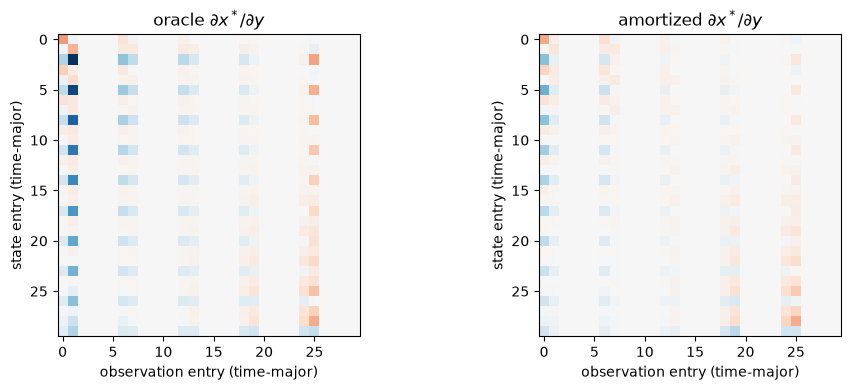

In [6]:
w = 1


def fast_fn(y):
    return amortized_solve(y[None])[0][0]


def oracle_fn(y):
    # Differentiate through the solve started from the start the multi-start selected.
    return rollout(minimise_from(starts[best_start[w]], y))


J_fast = jax.jacrev(fast_fn)(y_eval[w]).reshape(T_WIN * 3, T_WIN * 3)
J_oracle = jax.jacrev(oracle_fn)(y_eval[w]).reshape(T_WIN * 3, T_WIN * 3)
rel_err = float(jnp.linalg.norm(J_fast - J_oracle, 2) / jnp.linalg.norm(J_oracle, 2))
print(f"relative operator-norm difference of the Jacobians: {rel_err:.3f}")

y_ref, x_ref = y_eval[w], traj_oracle[w]


def oracle_linearised(y):
    return x_ref + (J_oracle @ (y - y_ref).ravel()).reshape(T_WIN, 3)


for threshold in (0.05, 0.25, 0.5):
    try:
        assert_adjoint_calibrated(fast_fn, oracle_linearised, y_ref, key=jax.random.PRNGKey(4), threshold=threshold, n_probes=10)
        print(f"threshold {threshold:.2f}: pass")
    except AssertionError as e:
        print(f"threshold {threshold:.2f}: {e}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
v = float(jnp.max(jnp.abs(J_oracle)))
axes[0].imshow(J_oracle, cmap="RdBu_r", vmin=-v, vmax=v)
axes[0].set_title(r"oracle $\partial x^*/\partial y$")
axes[1].imshow(J_fast, cmap="RdBu_r", vmin=-v, vmax=v)
axes[1].set_title(r"amortized $\partial x^*/\partial y$")
for ax in axes:
    ax.set_xlabel("observation entry (time-major)")
    ax.set_ylabel("state entry (time-major)")
plt.tight_layout()
plt.show()

The two Jacobians share their structure — the oracle's columns for
unobserved entries are exactly zero (the mask), and the amortized
model has learned to ignore them too; the diagonal blocks show each
observation pulling its own time, the off-diagonal ones the dynamics
spreading information along the window. Quantitatively they differ by
well over the 5 % an operational gate demands. That is the expected
failure for a network trained on values alone: nothing in the
likelihood objective constrains derivatives, and matching them takes
either far more data or an explicit Sobolev term in the loss.

## 6. Gate 3 — simulation-based calibration

The same SBC as in notebook 14, now with samples from the amortized
Gaussian (99 samples, so that the 100 possible ranks fill ten bins
evenly). The prior draws are test windows the network never trained
on.

SBC rank-histogram chi^2 = 90.1 on 9 dof (p = 0.000)
coverage of the amortized 1-sigma interval: 0.664 (nominal 0.683); 2-sigma: 0.936 (nominal 0.954)


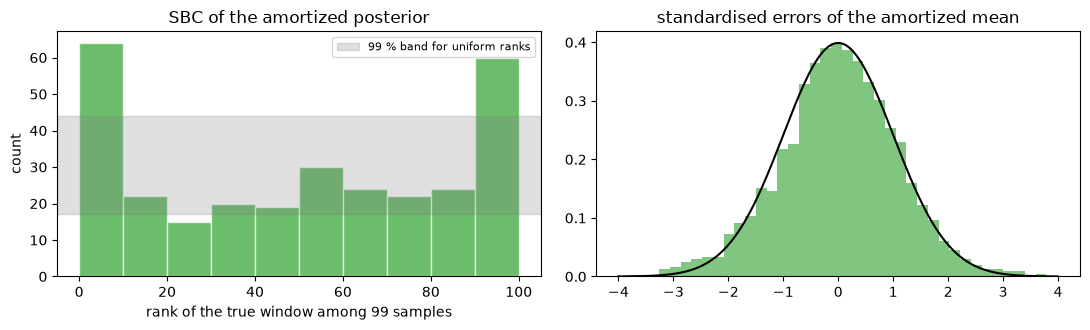

In [7]:
def sample_prior(key):
    return x_test[jax.random.randint(key, (), 0, x_test.shape[0])]


def sample_posterior(y, key, n):
    batch = Batch1D(input=(y * mask - MU * mask)[None] / SD, mask=mask[None])
    return unstandardise(model.sample(batch, key, n)[0])


N_RUNS, N_SAMPLES = 300, 99  # 100 possible ranks, so ten bins of ten
ranks = simulation_based_calibration(sample_posterior, sample_prior, observe,
                                     key=jax.random.PRNGKey(5), n_runs=N_RUNS, n_samples=N_SAMPLES)
n_bins = 10
counts, edges = np.histogram(np.asarray(ranks), bins=n_bins, range=(0, N_SAMPLES + 1))
lo, hi = stats.binom.ppf([0.005, 0.995], N_RUNS, 1.0 / n_bins)
chi2 = float(np.sum((counts - N_RUNS / n_bins) ** 2 / (N_RUNS / n_bins)))
print(f"SBC rank-histogram chi^2 = {chi2:.1f} on {n_bins - 1} dof (p = {1 - stats.chi2.cdf(chi2, n_bins - 1):.3f})")

# Per-entry coverage of the amortized intervals on the evaluation windows.
z_cal = (x_eval - mean_amort) / jnp.sqrt(var_amort)
print(f"coverage of the amortized 1-sigma interval: {float(jnp.mean(jnp.abs(z_cal) < 1)):.3f} (nominal 0.683); "
      f"2-sigma: {float(jnp.mean(jnp.abs(z_cal) < 2)):.3f} (nominal 0.954)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(edges[:-1], counts, width=np.diff(edges), align="edge", color="tab:green", alpha=0.7, edgecolor="white")
axes[0].axhspan(lo, hi, color="gray", alpha=0.25, label="99 % band for uniform ranks")
axes[0].set_xlabel(f"rank of the true window among {N_SAMPLES} samples")
axes[0].set_ylabel("count")
axes[0].set_title("SBC of the amortized posterior")
axes[0].legend(fontsize=8)
grid = jnp.linspace(-4, 4, 200)
axes[1].hist(np.asarray(jnp.clip(z_cal.ravel(), -4, 4)), bins=40, density=True, color="tab:green", alpha=0.6)
axes[1].plot(grid, stats.norm.pdf(grid), color="black")
axes[1].set_title("standardised errors of the amortized mean")
plt.tight_layout()
plt.show()

The rank histogram is U-shaped: the true window's norm falls in the
tails of the sample norms far more often than it should, the
signature of an over-confident posterior. Yet the marginal coverage
on the right is only a little below nominal. The two readings are
consistent, and the difference between them is the diagonal
covariance. The true posterior is strongly correlated along the window
(every state is a function of the same initial condition), and the
norm of a correlated vector varies far more than the norm of an
independent one with the same marginals; samples drawn without the
correlations therefore cluster in norm, and the truth lands outside
the cluster. SBC on a summary statistic sees what marginal coverage
cannot, which is why the gate uses one — and why the next head to
try is one that can represent correlations.

## Summary

- Amortized inference replaces a per-window optimisation with a
  network evaluation; training by maximum likelihood on simulated
  pairs is posterior matching in expectation over the data.
- The regression head reaches the oracle's accuracy at a tiny fraction
  of its cost, with a diagonal Gaussian uncertainty of about the
  oracle's size.
- The gates grade it honestly: it passes posterior agreement only at a
  loose tolerance, fails adjoint calibration by a wide margin, and its
  marginals are slightly over-confident while its samples ignore the
  within-window correlations, which the SBC histogram exposes as a
  U-shape.
- What the gates flag is what the next models fix: a flow or score
  head for the covariance structure, derivative-aware training for the
  Jacobian, and distillation against the oracle for the mean.

This closes the arc that began with notebook
[01](01_model_based_4dvar_L63.ipynb): the same observations, the same
dynamics, and now a menu of estimators from exact-but-slow to
fast-but-audited, with the tools to say which is which.